In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

#define paths
DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

#load processed dataset
df = pd.read_csv(PROCESSED_DIR / "merged_dataset.csv")

#this is just to set visualization style for more comfortable visual
sns.set_theme(style="whitegrid")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (110, 9)


,country,year,daly_rate,daly_lower,daly_upper,gdp_per_capita,oop_expenditure,health_expenditure_per_capita,urban_population
0,Brunei Darussalam,2010,10.127763,7.606276,13.710537,34937.555536,8.261349,795.977661,75.250656
1,Brunei Darussalam,2011,10.322006,7.662837,13.878036,46382.827426,8.471869,864.637878,75.312126
2,Brunei Darussalam,2012,10.728791,8.072679,14.623273,46968.597116,8.851929,869.365540,75.271423
3,Brunei Darussalam,2013,11.204321,8.369203,15.556143,44003.064427,9.407419,835.324524,75.175692
4,Brunei Darussalam,2014,11.727929,8.784243,16.022641,41026.508425,7.334599,785.412109,75.057264


In [ ]:
#check. We expect to see 11 countries, 10 years -> 110 observations in total
print("Countries:", df["country"].nunique())
print("Years:", sorted(df["year"].unique()))
print("Observations:", len(df))

Countries: 11
Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019)]
Observations: 110


In [9]:
#notice their mean, std, min, 3Q and max values of them
variables = [
    "daly_rate",
    "gdp_per_capita",
    "oop_expenditure",
    "health_expenditure_per_capita",
    "urban_population"
]
descriptive_stats = df[variables].describe().T
descriptive_stats

#save the results
descriptive_stats.to_csv(
    FIGURES_DIR / "descriptive_statistics.csv"
)

In [10]:
#check their missing values again to make sure there's none new after merging
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})
missing_values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   country                        110 non-null    str    
 1   year                           110 non-null    int64  
 2   daly_rate                      110 non-null    float64
 3   daly_lower                     110 non-null    float64
 4   daly_upper                     110 non-null    float64
 5   gdp_per_capita                 110 non-null    float64
 6   oop_expenditure                110 non-null    float64
 7   health_expenditure_per_capita  110 non-null    float64
 8   urban_population               110 non-null    float64
dtypes: float64(7), int64(1), str(1)
memory usage: 7.9 KB


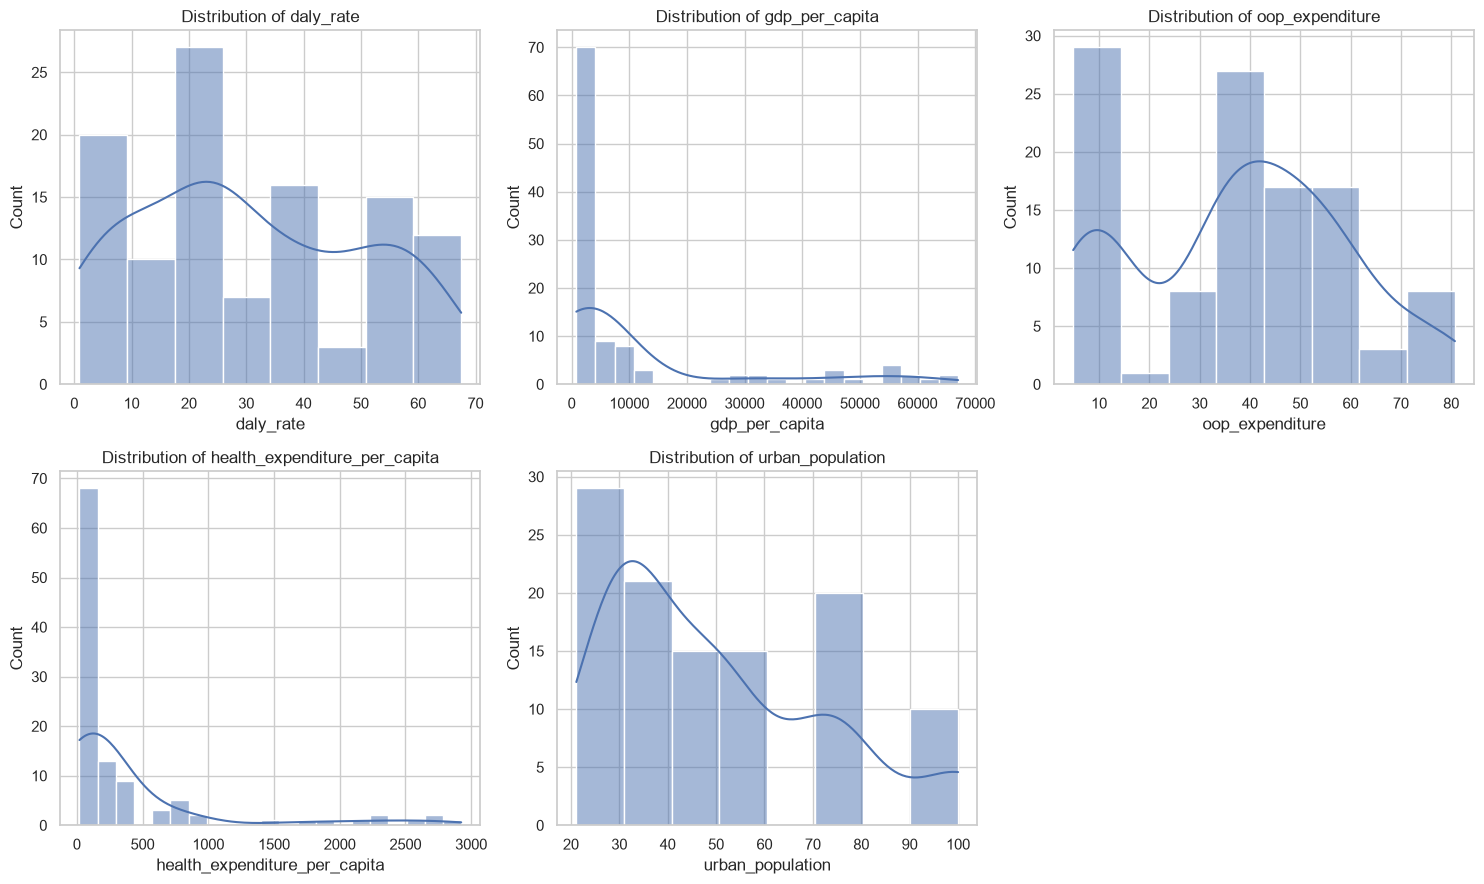

In [11]:
#draw histograms and KDE for 5 main variables
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, variable in zip(axes.flat, variables):
    sns.histplot(
        data=df,
        x=variable,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {variable}")
axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "variable_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#you should check if any graph is skewed and potential outliers, and wheter DALY rate is greatly different between observations

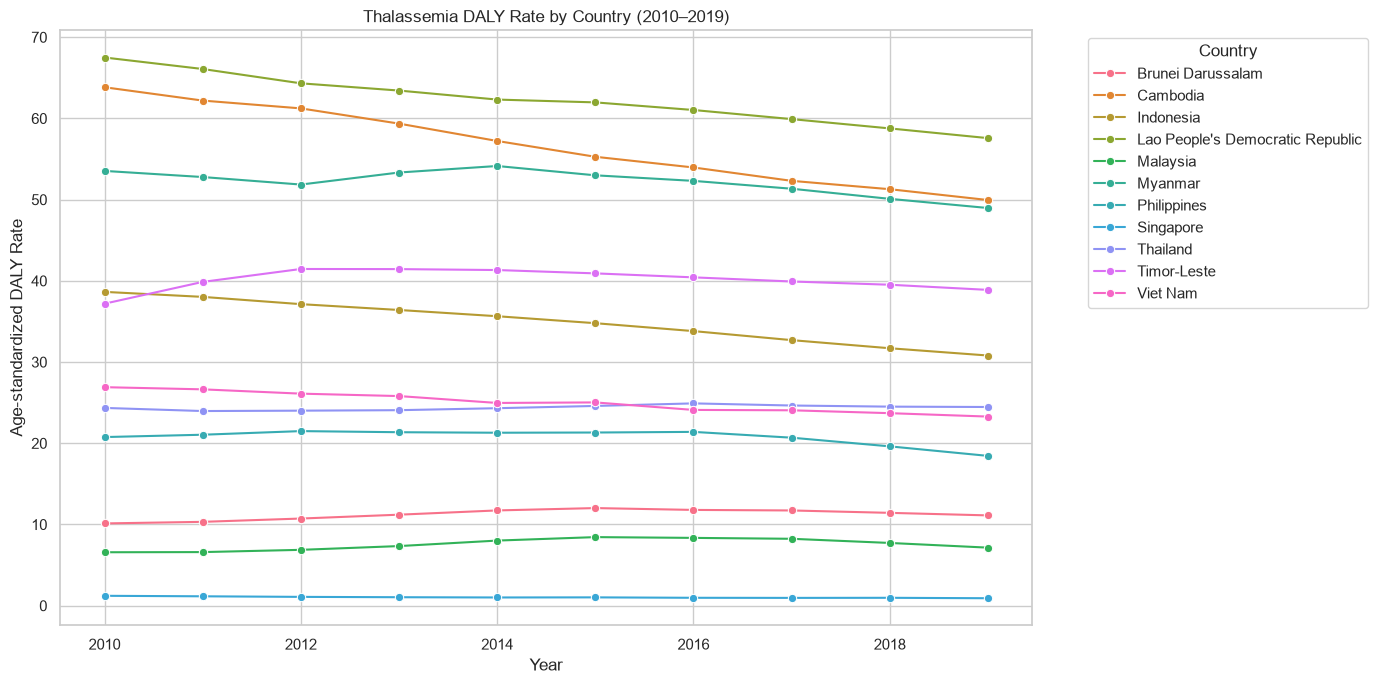

In [ ]:
#daly rate by time for 11 countries (very important for RQ1 !!!)
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=df,
    x="year",
    y="daly_rate",
    hue="country",
    marker="o"
)
plt.title("Thalassemia DALY Rate by Country (2010–2019)")
plt.xlabel("Year")
plt.ylabel("Age-standardized DALY Rate")
plt.legend(
    title="Country",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "daly_rate_trends_by_country.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#check for which country has highest DALY rate? and lowest?
#is it increase, decrease or quite stable by time?
#is there any abnormal trend

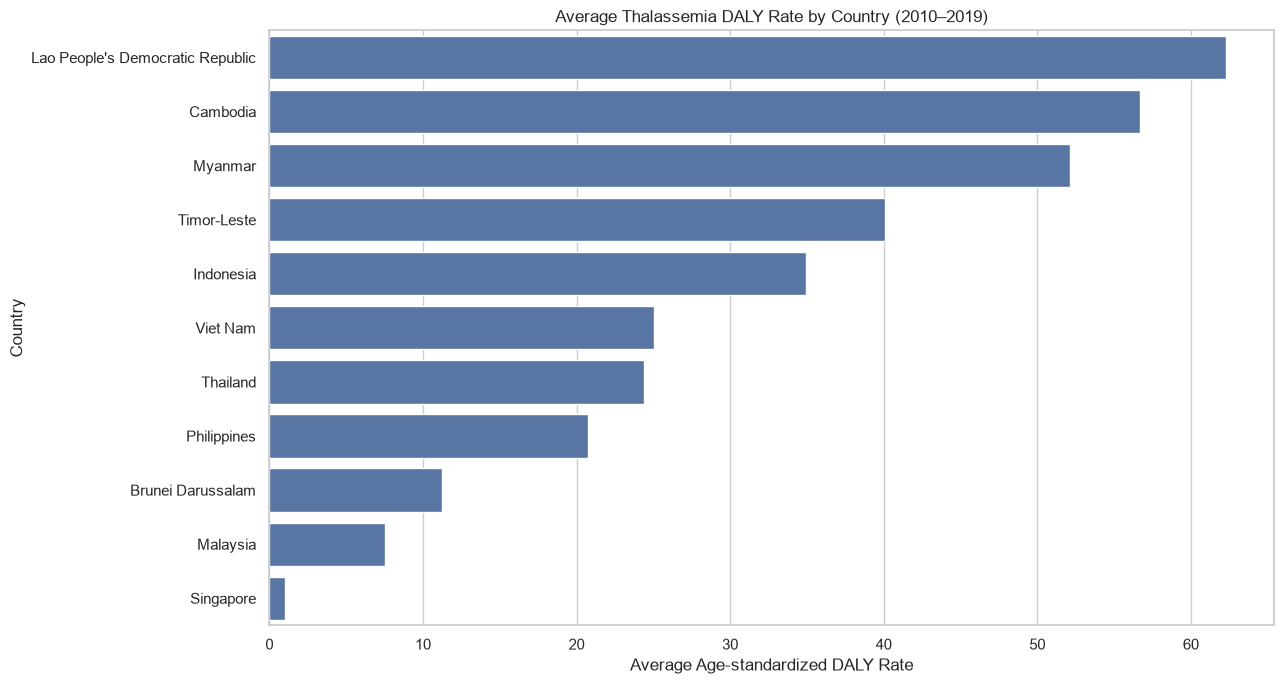

In [13]:
#or a bar chart for average DALY rate in 2010-2019
country_avg = (
    df.groupby("country")["daly_rate"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)
plt.figure(figsize=(13, 7))
sns.barplot(
    data=country_avg,
    x="daly_rate",
    y="country"
)
plt.title("Average Thalassemia DALY Rate by Country (2010–2019)")
plt.xlabel("Average Age-standardized DALY Rate")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "average_daly_rate_by_country.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

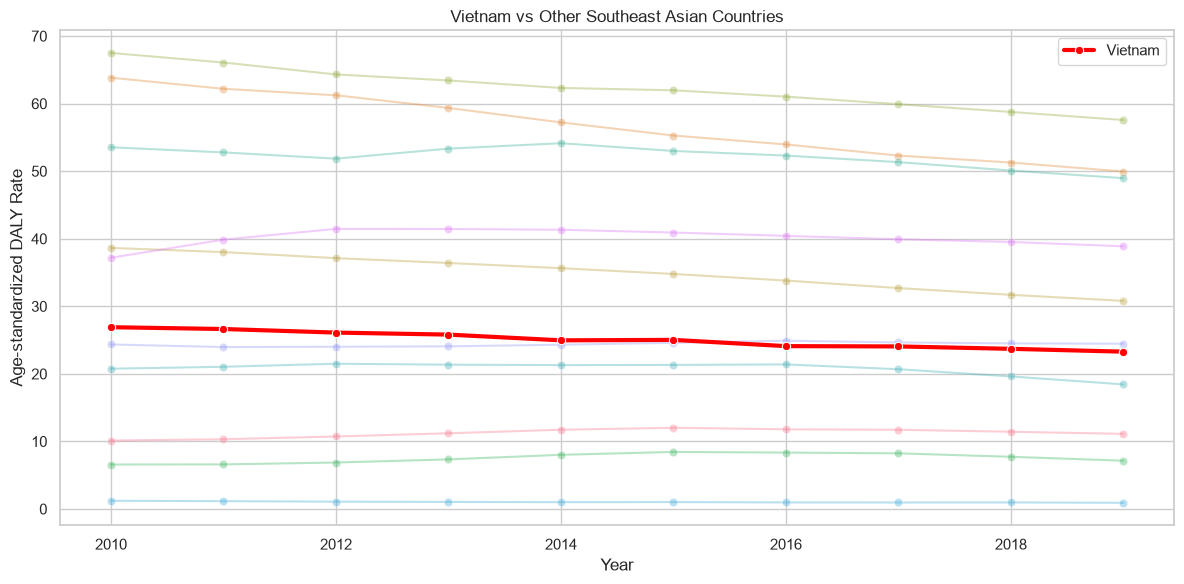

In [ ]:
#highlight to compare vietnam to the other SEA countries
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="year",
    y="daly_rate",
    hue="country",
    marker="o",
    alpha=0.35,
    legend=False
)
vietnam = df[df["country"] == "Viet Nam"]
sns.lineplot(
    data=vietnam,
    x="year",
    y="daly_rate",
    color="red",
    marker="o",
    linewidth=3,
    label="Vietnam"
)
plt.title("Vietnam vs Other Southeast Asian Countries")
plt.xlabel("Year")
plt.ylabel("Age-standardized DALY Rate")
plt.legend()
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "vietnam_vs_southeast_asia.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

#check where Vietname is compared to other countries, and what is its trend?

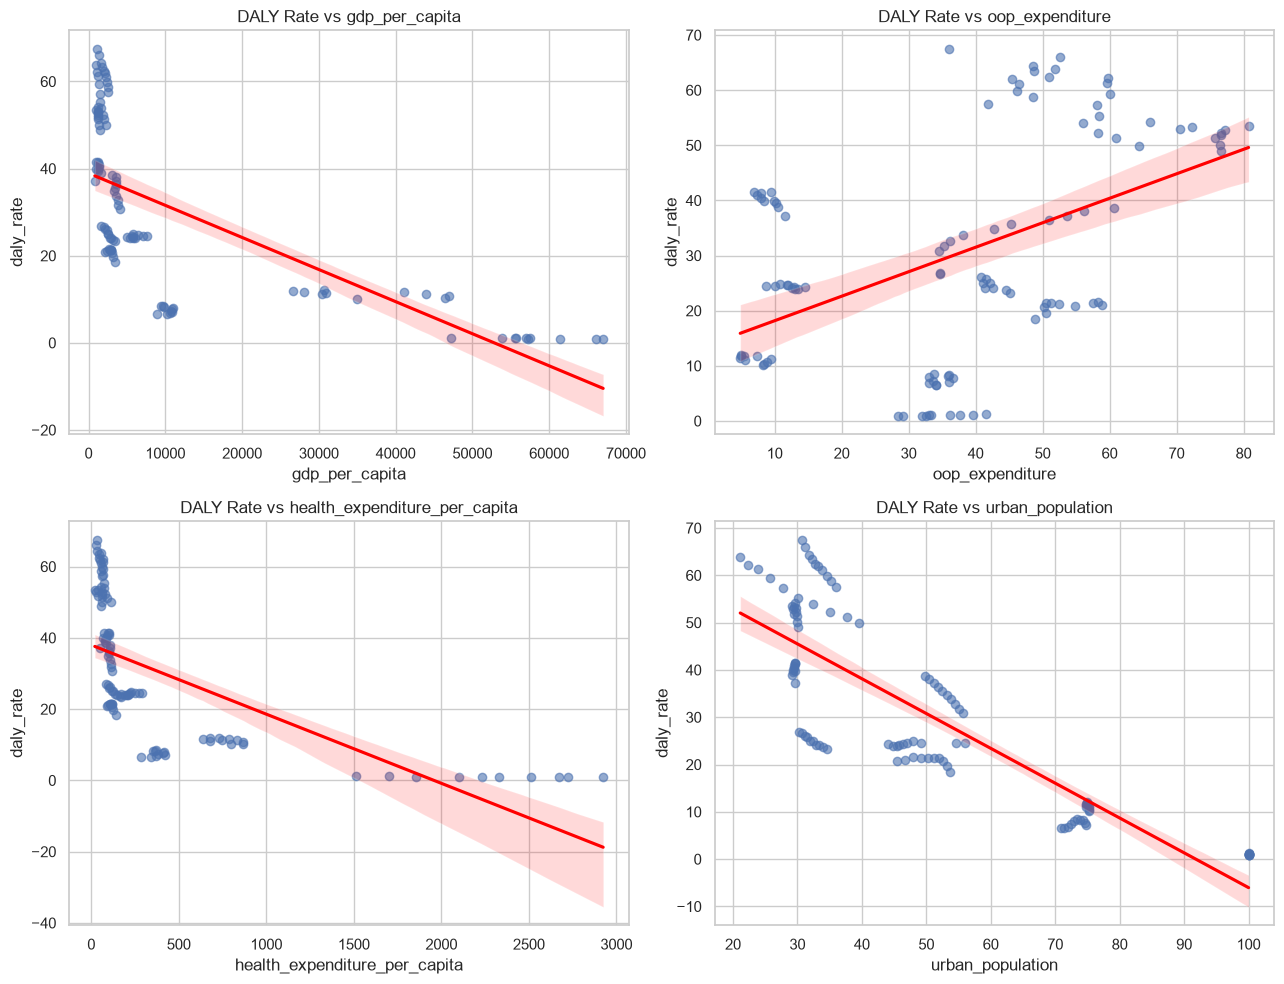

In [17]:
#scatter plot
predictors = [
    "gdp_per_capita",
    "oop_expenditure",
    "health_expenditure_per_capita",
    "urban_population"
]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, predictor in zip(axes.flat, predictors):
    sns.regplot(
        data=df,
        x=predictor,
        y="daly_rate",
        scatter_kws={"alpha": 0.6},
        line_kws={"color": "red"},
        ax=ax
    )
    ax.set_title(f"DALY Rate vs {predictor}")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "daly_rate_vs_predictors.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

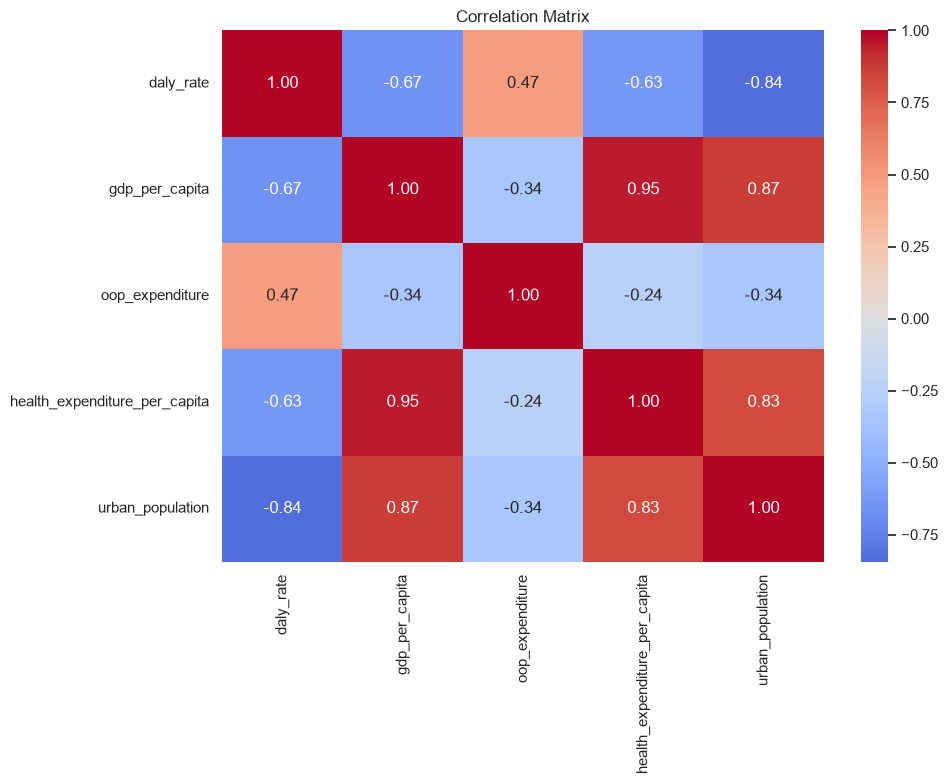

In [18]:
#correlation matrix: which predictors tend to have positive or negative corr with DALY rate?
#whose corr is nearly 0?
#strong corr or not?
correlation_matrix = df[
    ["daly_rate"] + predictors
].corr(method="pearson")
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "correlation_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [19]:
#summary
#real real number of observations after merging. We expect 110 but let's see
print("Number of observations:", len(df))
print("Number of countries:", df["country"].nunique())
print("Number of years:", df["year"].nunique())
print("\nObservations per country:")
print(df.groupby("country").size())
#and no missing value is the best. Save the result
missing_values.to_csv(
    FIGURES_DIR / "missing_values_summary.csv"
)

Number of observations: 110
Number of countries: 11
Number of years: 10

Observations per country:
country
Brunei Darussalam                   10
Cambodia                            10
Indonesia                           10
Lao People's Democratic Republic    10
Malaysia                            10
Myanmar                             10
Philippines                         10
Singapore                           10
Thailand                            10
Timor-Leste                         10
Viet Nam                            10
dtype: int64
